# КТ 1 — EDA сырого корпуса

Корпус собран скриптом `scripts/build_corpus.py` (описание источников и решений — в `reports/kt1.md`).
Здесь он анализируется **до какой-либо чистки**: HTML-разметка, эмодзи, ссылки и дубликаты на месте.

Вопросы, на которые отвечает EDA:
1. Какой типичный размер документа и насколько он варьируется?
2. Что составляет основной шум в данных?
3. Какие тематические кластеры есть в корпусе?
4. Какие проблемы это создаст для чанкинга и ретрива?

In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import gigarag.dedup
import gigarag.embeddings
import gigarag.noise
import gigarag.patterns
import gigarag.text
from gigarag import dedup, noise, patterns, stats, topics
from gigarag.cache import (
    CacheStore,
    code_fingerprint,
    load_or_compute,
    read_json,
    read_npy,
    read_parquet,
    write_json,
    write_npy,
    write_parquet,
)
from gigarag.corpus import read_jsonl
from gigarag.text import is_mostly_latin, visible_text

pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd().parent  # ноутбук исполняется из notebooks/
DATA = ROOT / "data"
rows, CORPUS_SHA = read_jsonl(DATA / "corpus.jsonl")
cache = CacheStore(DATA / "cache", CORPUS_SHA)
# Отпечатки кода, от которого зависят результаты: правка регулярок или формул сама меняет ключи кэшей.
TEXT_CODE = code_fingerprint(gigarag.patterns, gigarag.text)
NOISE_CODE = code_fingerprint(gigarag.patterns, gigarag.noise)
DEDUP_CODE = code_fingerprint(gigarag.patterns, gigarag.text, gigarag.dedup)
EMB_CODE = code_fingerprint(gigarag.patterns, gigarag.text, gigarag.embeddings)

df = pd.DataFrame(rows)
assert df["doc_id"].is_unique
df["date"] = pd.to_datetime(df["date"])
df["visible"] = df["text"].map(visible_text)
print("документов с HTML-сущностями:", df["text"].map(patterns.has_html_entity).sum())
print(len(df), "документов, sha256 корпуса:", CORPUS_SHA[:16])

документов с HTML-сущностями: 285
19665 документов, sha256 корпуса: 76b0676b841020e9


## 1. Состав корпуса

In [2]:
by_src = df.groupby("source").agg(docs=("doc_id", "size"), first=("date", "min"), last=("date", "max"))
by_src["share_%"] = stats.share_percent(by_src["docs"]).round(1)
by_src

,docs,first,last,share_%
source,,,,
dota2ru_article,36,2023-08-09,2026-09-15,0.2
dota2ru_comment,2692,2023-08-08,2026-09-30,13.7
patchnotes,3447,2023-08-08,2026-09-15,17.5
tg_Dota2,6589,2023-08-08,2026-10-24,33.5
tg_gabenews,6901,2023-08-30,2026-10-24,35.1


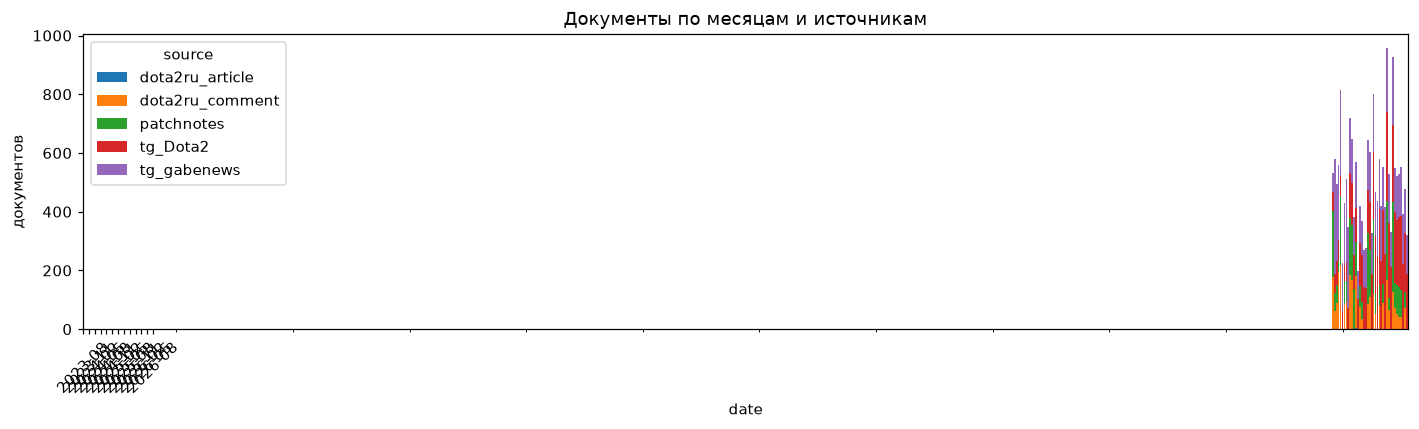

In [3]:
monthly = df.groupby([df["date"].dt.to_period("M"), "source"]).size().unstack(fill_value=0)
ax = monthly.plot(kind="bar", stacked=True, figsize=(13, 4), width=0.9)
ax.set_xticks(range(0, len(monthly), 3))
ax.set_xticklabels([str(p) for p in monthly.index[::3]], rotation=45)
ax.set_title("Документы по месяцам и источникам")
ax.set_ylabel("документов")
plt.tight_layout()

## 2. Длины документов

Токены считаются токенизатором **BGE-M3** (XLM-RoBERTa, SentencePiece) — это одна из моделей,
которыми корпус будет индексироваться дальше, так что длины близки к реальным.
Считаем два варианта: сырой текст (как его увидел бы наивный пайплайн, с HTML) и видимый текст без тегов.

In [4]:
from transformers import AutoTokenizer

TOKENIZER = "BAAI/bge-m3"
TOKENIZER_REV = "5617a9f61b028005a4858fdac845db406aefb181"  # фиксированный commit на Hugging Face
tok = AutoTokenizer.from_pretrained(TOKENIZER, revision=TOKENIZER_REV)


def token_lengths(texts) -> list[int]:
    return [len(ids) for ids in tok(list(texts), add_special_tokens=False)["input_ids"]]


lens = load_or_compute(
    cache.path("token_lens", "parquet", tokenizer=TOKENIZER, revision=TOKENIZER_REV, code=TEXT_CODE),
    lambda: pd.DataFrame({"doc_id": df["doc_id"], "tok_raw": token_lengths(df["text"]),
                          "tok_visible": token_lengths(df["visible"])}),
    load=read_parquet, save=write_parquet,
)
n_before = len(df)
df = df.merge(lens, on="doc_id", how="left", validate="one_to_one")
assert len(df) == n_before and df["tok_raw"].notna().all(), "кэш длин не покрывает корпус"
print("токенов всего: сырых", df["tok_raw"].sum(), "| видимых", df["tok_visible"].sum())

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (97207 > 8192). Running this sequence through the model will result in indexing errors


токенов всего: сырых 9917946 | видимых 1887206


In [5]:
SHORT, LONG = 50, 2000  # пороги выбросов из ТЗ, в токенах

print("Видимый текст:")
display(stats.length_summary(df, "tok_visible", by="source", short=SHORT, long=LONG))
print("Сырой текст с разметкой:")
display(stats.length_summary(df, "tok_raw", by="source", short=SHORT, long=LONG))

Видимый текст:


,count,mean,std,min,10%,50%,90%,max,<50_%,>2000_%
source,,,,,,,,,,
dota2ru_article,36.0,8167.6,11407.8,1177.0,1868.0,3341.0,20105.5,46096.0,0.0,83.3
dota2ru_comment,2692.0,30.5,33.5,0.0,6.0,21.0,64.0,502.0,83.9,0.0
patchnotes,3447.0,94.0,130.7,10.0,24.0,54.0,203.4,2226.0,45.8,0.1
tg_Dota2,6589.0,74.2,56.1,0.0,35.0,57.0,134.2,956.0,37.3,0.0
tg_gabenews,6901.0,101.2,76.1,10.0,35.0,80.0,192.0,870.0,25.9,0.0
ВСЕГО,19665.0,96.0,598.2,0.0,23.0,58.0,163.0,46096.0,41.1,0.2


Сырой текст с разметкой:


,count,mean,std,min,10%,50%,90%,max,<50_%,>2000_%
source,,,,,,,,,,
dota2ru_article,36.0,51336.7,57152.7,13491.0,15639.5,26752.0,115746.0,233904.0,0.0,100.0
dota2ru_comment,2692.0,74.1,57.0,21.0,35.0,55.0,124.0,801.0,41.5,0.0
patchnotes,3447.0,94.5,132.9,10.0,24.0,54.0,204.0,2226.0,45.6,0.1
tg_Dota2,6589.0,434.8,621.1,33.0,182.0,248.0,775.2,6815.0,0.1,2.9
tg_gabenews,6901.0,678.1,486.6,73.0,295.0,514.0,1252.0,6974.0,0.0,2.0
ВСЕГО,19665.0,504.3,3290.5,10.0,41.0,272.0,929.6,233904.0,13.7,1.9


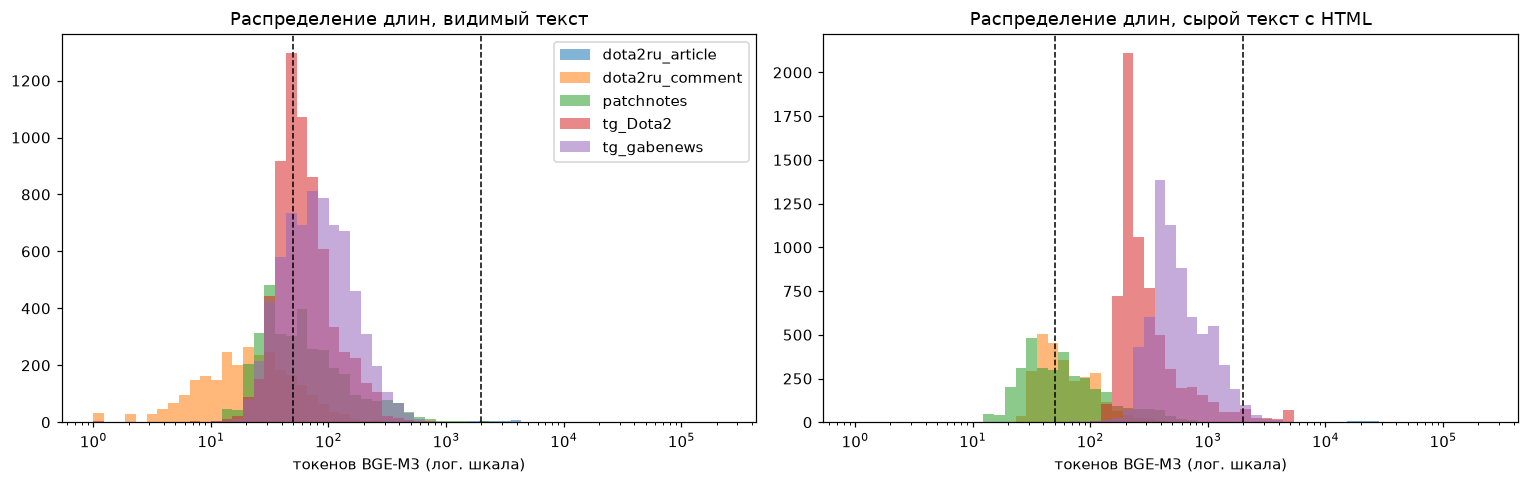

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
bins = np.logspace(0, np.log10(df["tok_raw"].max() + 1), 60)
for ax, col, title in zip(axes, ["tok_visible", "tok_raw"], ["видимый текст", "сырой текст с HTML"], strict=True):
    for src, g in df.groupby("source"):
        ax.hist(g[col].clip(lower=1), bins=bins, alpha=0.55, label=src)
    ax.set_xscale("log")
    ax.axvline(SHORT, color="k", ls="--", lw=1)
    ax.axvline(LONG, color="k", ls="--", lw=1)
    ax.set_title(f"Распределение длин, {title}")
    ax.set_xlabel("токенов BGE-M3 (лог. шкала)")
axes[0].legend()
plt.tight_layout()

Примеры выбросов: самые короткие и самые длинные документы.

In [7]:
cols = ["source", "tok_visible", "visible"]
display(df[df["tok_visible"] < 5].sample(8, random_state=1)[cols])
display(df.nlargest(5, "tok_visible")[["source", "tok_visible", "tok_raw", "title"]])

,source,tok_visible,visible
4190,dota2ru_comment,0,
4553,dota2ru_comment,3,что с ним
3706,dota2ru_comment,4,Тогда это уже вино
5838,dota2ru_comment,0,
4333,dota2ru_comment,4,Дежавю.
3526,dota2ru_comment,4,Боби мид
3701,dota2ru_comment,2,манта
5505,dota2ru_comment,0,


,source,tok_visible,tok_raw,title
4359,dota2ru_article,46096,211056,В Dota 2 вышел глобальный патч 7.36. Добавлены две новые механики: врождённые способности и аспекты
5768,dota2ru_article,39168,233904,В Dota 2 вышел патч 7.41 — удалены аспекты
5001,dota2ru_article,38754,186260,В Dota 2 вышел патч 7.38 «Вольные воды»
5536,dota2ru_article,22060,132012,"В Dota 2 вышел патч 7.40 — изменения карты, балансные правки и обновлённый порядок драфта в CM"
5196,dota2ru_article,18151,99480,В Dota 2 вышел патч 7.39 «Весенняя встряска»


## 3. Шум: доля «мусорных» токенов

Доли считаются **в токенах BGE-M3** — тех же единицах, что и длины выше, то есть это доля
входного окна модели. Каждому символу сырого текста присваивается класс, токен получает класс
своего первого символа (по `offset_mapping` токенизатора). Приоритет классов при пересечении:
URL (в том числе в `href`/`src`) > HTML-тег или HTML-сущность (`&nbsp;`) > эмодзи > число > пунктуация >
прочий спецсимвол > буквы.

* **Удаляемый шум** — кандидаты на удаление в КТ 2: HTML, URL, эмодзи, прочие спецсимволы
  (`|`, `#`, `@`, `→`, декоративные символы).
* **Не шум** — буквы, числа и обычная пунктуация. Числа показаны отдельно: в патчноутах это суть
  правки («урон увеличен с 75 до 80»), удалять их нельзя.

In [8]:
def token_offsets(text: str):
    return tok(text, add_special_tokens=False, return_offsets_mapping=True)["offset_mapping"]


def compute_token_classes() -> pd.DataFrame:
    counts = np.vstack([noise.token_class_counts(t, token_offsets) for t in df["text"]])
    return pd.DataFrame(counts, columns=noise.CLASS_NAMES).assign(doc_id=df["doc_id"].values)


token_classes = load_or_compute(
    cache.path("token_classes", "parquet", tokenizer=TOKENIZER, revision=TOKENIZER_REV, code=NOISE_CODE),
    compute_token_classes, load=read_parquet, save=write_parquet,
)
assert token_classes["doc_id"].tolist() == df["doc_id"].tolist(), "кэш классов не совпадает с корпусом"
token_classes["source"] = df["source"].values

share = noise.class_shares_percent(token_classes, by="source")
share["удаляемый_шум_%"] = noise.removable_noise_percent(share)
share.round(1)

,word,num,punct,special,emoji,html,url,удаляемый_шум_%
source,,,,,,,,
dota2ru_article,13.4,1.6,1.1,0.8,0.0,82.6,0.4,83.9
dota2ru_comment,36.4,0.8,4.0,0.2,0.0,57.5,1.0,58.7
patchnotes,71.3,11.4,12.3,4.3,0.0,0.6,0.0,4.9
tg_Dota2,13.3,0.6,1.4,0.4,1.0,80.9,2.4,84.6
tg_gabenews,11.3,0.4,1.3,0.4,1.0,82.9,2.8,87.0
ВСЕГО,14.7,1.1,1.7,0.6,0.7,79.1,2.1,82.5


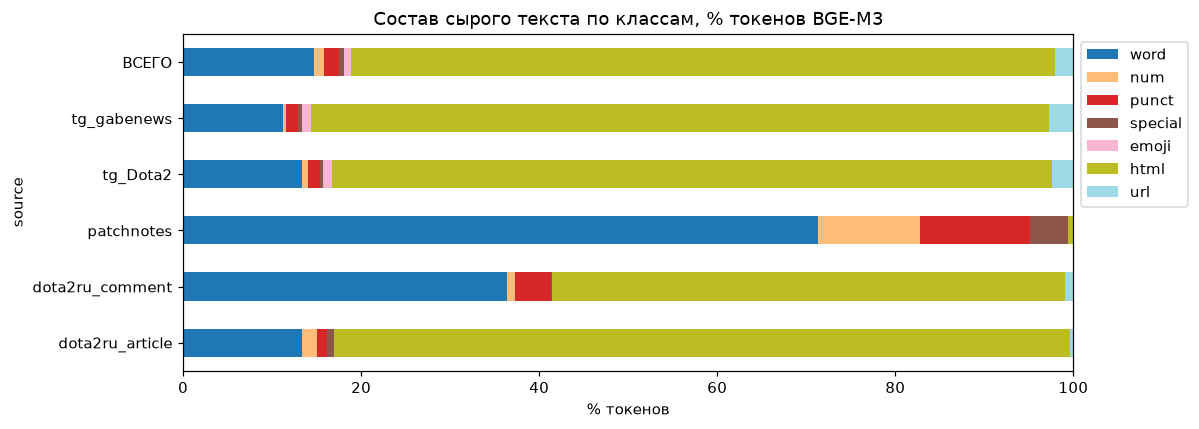

In [9]:
share[noise.CONTENT_CLASSES].plot(kind="barh", stacked=True, figsize=(11, 4), colormap="tab20")
plt.title("Состав сырого текста по классам, % токенов BGE-M3")
plt.xlabel("% токенов")
plt.legend(bbox_to_anchor=(1, 1))
plt.tight_layout()

Дополнительные признаки «грязи» по источникам: доля документов с эмодзи, ссылками, цитатами,
пересылками, медиа без текста, а также рекламные маркеры в Telegram.

In [10]:
flags = pd.DataFrame({
    "source": df["source"],
    "с эмодзи": token_classes["emoji"].values > 0,
    "со ссылкой": df["text"].map(patterns.has_url),
    "с цитатой": df["meta"].map(lambda m: bool(m.get("has_quote"))),
    "пересылка": df["meta"].map(lambda m: bool(m.get("forwarded_from"))),
    "медиа": df["meta"].map(lambda m: bool(m.get("has_photo") or m.get("has_video"))),
    "реклама/ставки": df["visible"].map(patterns.has_ads_marker),
    "латиница>50%": df["visible"].map(is_mostly_latin),
})
(flags.groupby("source").mean() * 100).round(1)

,с эмодзи,со ссылкой,с цитатой,пересылка,медиа,реклама/ставки,латиница>50%
source,,,,,,,
dota2ru_article,0.0,100.0,0.0,0.0,0.0,0.0,0.0
dota2ru_comment,0.0,0.8,0.0,0.0,0.0,0.1,0.8
patchnotes,0.0,0.0,0.0,0.0,0.0,0.0,1.8
tg_Dota2,99.5,92.3,0.0,2.7,99.3,0.6,1.1
tg_gabenews,99.8,93.4,0.0,0.2,95.8,0.9,3.8


## 4. Дубликаты и near-duplicates

Только фиксируем, ничего не удаляем (удаление — шаг предобработки КТ 2).
* **Точные** — совпадение видимого текста после приведения к нижнему регистру и схлопывания пробелов.
* **Почти-дубликаты** — пары с Jaccard ≥ 0.8 по множествам словесных 3-грамм. MinHash LSH
  (128 перестановок) используется только для генерации кандидатов, причём с заниженным порогом 0.5:
  LSH ошибается в обе стороны, и при пороге, равном итоговому, часть настоящих пар не попадает в кандидаты.
  Для каждой пары-кандидата Jaccard пересчитывается точно, пары ниже 0.8 отбрасываются.
  Документы короче 5 слов не участвуют — у них почти нет шинглов.

In [11]:
norm = df["visible"].map(dedup.normalize_for_dedup)
h = norm.map(dedup.content_hash)
dup_groups = h[h.duplicated(keep=False)].groupby(h).size()
exact = pd.DataFrame({"source": df["source"], "exact_dup": h.duplicated(keep="first")})
print(f"Точные дубликаты: {exact['exact_dup'].sum()} лишних копий ({exact['exact_dup'].mean()*100:.1f}% корпуса), "
      f"групп {len(dup_groups)}")
display(exact.groupby("source")["exact_dup"].agg(["sum", "mean"])
        .assign(mean=lambda x: (x["mean"] * 100).round(1)).rename(columns={"sum": "копий", "mean": "%"}))
top = (df.loc[h.isin(dup_groups.nlargest(6).index)].groupby(h)["visible"].agg(["size", "first"])
       .sort_values("size", ascending=False))
top

Точные дубликаты: 432 лишних копий (2.2% корпуса), групп 316


,копий,%
source,,
dota2ru_article,0,0.0
dota2ru_comment,44,1.6
patchnotes,12,0.3
tg_Dota2,237,3.6
tg_gabenews,139,2.0


,size,first
visible,,
331c725db66a295968e9ec5c5b4cea54,22,Данный комментарий был удален.
d41d8cd98f00b204e9800998ecf8427e,22,
687f2a2ef65cff682caf46e04c4819d6,16,🏆 Еженедельный мета-отчет Эти герои показывают себя лучше других на 7.000+ MMR Не забудь сохранить и поделиться с др...
05c93a62c47deec349d1836d3b93b04f,8,🎖 Мета-отчет нового патча После выхода обновления эти персонажи показывают себя лучше всех на высоком рейтинге Сохра...
926ae08934acd05c78b454b420b28eee,8,"🏆 Еженедельный мета-отчет Худшие герои на каждой роли на 7.000+ MMR Скинь другу, пусть не берет этих героев в рейтин..."
51e00500dedd820afba5d8e73a2f2095,5,"😮 В Dota вышел новый патч 7.37d, ниже самое интересное из обновления • Добавили новую сокровищницу Collector Cache 2..."


In [12]:
JACCARD = 0.8              # итоговый порог почти-дубликата (точный Jaccard)
CAND_THRESHOLDS = [0.4, 0.5, 0.6, 0.7, 0.8]
CAND_THRESHOLD = 0.5       # порог LSH для кандидатов — заметно ниже итогового, чтобы не терять пары
NUM_PERM = 128
shingles = dedup.shingle_sets(dict(zip(df["doc_id"], norm, strict=True)), n=3, min_words=5)


def compute_lsh_runs() -> dict:
    signatures = dedup.minhash_signatures(shingles, NUM_PERM)
    runs = (dedup.lsh_candidates(signatures, t, NUM_PERM) for t in CAND_THRESHOLDS)
    return {str(r.threshold): {"bands": r.bands, "rows": r.rows, "pairs": r.pairs} for r in runs}


lsh_runs = load_or_compute(
    cache.path("near_dup_candidates", "json", shingle=3, min_words=5, num_perm=NUM_PERM, seed=1,
               thresholds=CAND_THRESHOLDS, code=DEDUP_CODE),
    compute_lsh_runs, load=read_json, save=write_json,
)
hash_by_id = dict(zip(df["doc_id"], h, strict=True))


def non_exact(pairs) -> list[tuple[str, str]]:
    """Пары, которые не являются точными дубликатами (те посчитаны выше)."""
    return [(a, b) for a, b in pairs if hash_by_id[a] != hash_by_id[b]]


# Чувствительность к порогу LSH: сколько пар с точным Jaccard ≥ 0.8 находится при каждом пороге кандидатов
# и какова теоретическая вероятность, что пара ровно с J = 0.8 станет кандидатом.
display(pd.DataFrame([
    {"порог LSH": t, "bands b": run["bands"], "rows r": run["rows"],
     "P(кандидат | J=0.8)": round(dedup.lsh_candidate_probability(JACCARD, run["bands"], run["rows"]), 4),
     "кандидатов": len(non_exact(run["pairs"])),
     "подтверждено J≥0.8": len(dedup.confirmed_pairs(non_exact(run["pairs"]), shingles, JACCARD))}
    for t, run in ((t, lsh_runs[str(t)]) for t in CAND_THRESHOLDS)
]))

cand = non_exact(lsh_runs[str(CAND_THRESHOLD)]["pairs"])
pairs = dedup.confirmed_pairs(cand, shingles, JACCARD)
near_ids = {d for a, b, _ in pairs for d in (a, b)}
print(f"Порог кандидатов {CAND_THRESHOLD}: {len(cand)} кандидатов (не точных), "
      f"подтверждено точным Jaccard ≥ {JACCARD}: {len(pairs)} пар, "
      f"затронуто документов: {len(near_ids)} ({len(near_ids) / len(df) * 100:.1f}%)")
src = dict(zip(df["doc_id"], df["source"], strict=True))
pair_src = Counter(" ↔ ".join(sorted({src[a], src[b]})) if src[a] != src[b] else src[a] for a, b, _ in pairs)
pd.Series(pair_src, name="пар").sort_values(ascending=False).to_frame()

,порог LSH,bands b,rows r,P(кандидат | J=0.8),кандидатов,подтверждено J≥0.8
0,0.4,32,4,1.0000,4517,167
1,0.5,25,5,1.0000,1167,167
2,0.6,18,7,0.9855,485,167
3,0.7,14,9,0.8670,341,165
4,0.8,9,13,0.3988,182,156


Порог кандидатов 0.5: 1167 кандидатов (не точных), подтверждено точным Jaccard ≥ 0.8: 167 пар, затронуто документов: 316 (1.6%)


,пар
tg_Dota2,89
tg_gabenews,73
patchnotes,2
tg_Dota2 ↔ tg_gabenews,2
dota2ru_comment ↔ patchnotes,1


LSH — вероятностный метод, поэтому найденные пары — оценка снизу. Полнота обосновывается двумя способами:
теоретическая вероятность пропустить пару с J ≥ 0.8 при выбранном пороге кандидатов (столбец
`P(кандидат | J=0.8)`; для J > 0.8 она ещё выше) и выход числа подтверждённых пар на плато при снижении
порога LSH — дальнейшее снижение добавляет только кандидатов ниже 0.8, но не новые настоящие пары.

In [13]:
vis = dict(zip(df["doc_id"], df["visible"], strict=True))
rng = np.random.default_rng(0)
for a, b, j in [pairs[i] for i in rng.choice(len(pairs), size=min(4, len(pairs)), replace=False)]:
    print(f"Jaccard {j:.2f}\n[{src[a]}] {vis[a][:200]}\n[{src[b]}] {vis[b][:200]}\n" + "-" * 80)

Jaccard 1.00
[tg_Dota2] 🎁 Новые Immortal-предметы Участвуя в фэнтези и делая прогнозы на TI, можно получить имморталки , перекрашенные скины достались: Spirit Breaker Queen of Pain Phantom Lancer Lion Shadow Shaman Какую заб
[tg_Dota2] 🎁 Новые Immortal-предметы Участвуя в фэнтези и делая прогнозы на TI, можно получить имморталки, перекрашенные скины достались: Spirit Breaker Queen of Pain Phantom Lancer Lion Shadow Shaman Какую заби
--------------------------------------------------------------------------------
Jaccard 0.80
[tg_Dota2] 🗡 Керри с высоким винрейтом на каждом ранге от Dotabuff Лови список сильнейших героев на разном MMR в патче 7.41d Сохраняй себе и не забудь поделиться с друзьями! @Dota2
[tg_Dota2] 🗡 Керри с высоким винрейтом на каждом ранге от Dotabuff Лови список сильнейших героев на разном MMR в патче 7.41e Сохраняй себе и не забудь поделиться с друзьями! @Dota2
--------------------------------------------------------------------------------
Jaccard 1.00
[tg_gabenews]

## 5. Тематические кластеры

Видимый текст (первые 512 токенов) кодируется моделью `intfloat/multilingual-e5-small`
(на GPU, если он есть), затем KMeans. Ключевые слова кластера — c-TF-IDF: насколько термин
характерен именно для этого кластера по сравнению со всем корпусом.
Это разведочный анализ: цель — увидеть, из каких тем состоит корпус, а не выбрать модель.

In [14]:
from sklearn.feature_extraction.text import CountVectorizer

from gigarag import stopwords
from gigarag.clustering import deterministic_kmeans
from gigarag.embeddings import encode_passages
from gigarag.sources.topic_lexicon import CHANNEL_BOILERPLATE

EMB_MODEL = "intfloat/multilingual-e5-small"
EMB_REV = "614241f622f53c4eeff9890bdc4f31cfecc418b3"  # фиксированный commit на Hugging Face
emb = load_or_compute(
    cache.path("emb", "npy", model=EMB_MODEL, revision=EMB_REV, max_seq_length=512, prefix="passage: ", code=EMB_CODE),
    lambda: encode_passages(df["visible"].tolist(), EMB_MODEL, EMB_REV, max_seq_length=512, prefix="passage: "),
    load=read_npy, save=write_npy,
)
assert emb.shape[0] == len(df), "кэш эмбеддингов не совпадает с корпусом"

K = 14
df["cluster"] = deterministic_kmeans(emb, n_clusters=K, seed=42)

# Подписи каналов исключены: они есть почти в каждом посте и забивают верх любого кластера Telegram.
# Редкие опечатки отсекаются по документам (min_df=3), а не по кластерам — специфичные термины сохраняются.
vec = CountVectorizer(lowercase=True, min_df=3, tokenizer=patterns.topic_words, token_pattern=None,
                      stop_words=sorted(stopwords.RUSSIAN | stopwords.ENGLISH | CHANNEL_BOILERPLATE))
weights = topics.class_tfidf(topics.cluster_term_counts(vec.fit_transform(df["visible"]), df["cluster"].values, K))
clusters = pd.DataFrame({
    "docs": df.groupby("cluster").size(),
    "top_terms": [", ".join(t) for t in topics.top_terms(weights, vec.get_feature_names_out())],
})
clusters = clusters.join((pd.crosstab(df["cluster"], df["source"], normalize="index") * 100).round(0))
clusters.sort_values("docs", ascending=False)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,docs,top_terms,dota2ru_article,dota2ru_comment,patchnotes,tg_Dota2,tg_gabenews
cluster,,,,,,,
3,1979,"патч, уменьшен, увеличен, уменьшена, увеличена, урон, секунд, золота, бонус, маны",0.0,0.0,99.0,0.0,0.0
7,1926,"team, betboom, international, турнир, tundra, состав, команды, дайджест, команда, dreamleague",0.0,0.0,0.0,30.0,70.0
12,1923,"баг, героя, который, сет, использовать, нужно, предмет, знали, работает, аспектом",0.0,1.0,0.0,65.0,33.0
6,1769,"керри, играть, герой, просто, очень, героев, против, satanic, yatoro, героя",0.0,0.0,0.0,46.0,53.0
5,1679,"показал, решил, сет, головач, мастерской, серега, steam, ждем, база, патче",0.0,0.0,0.0,94.0,6.0
11,1626,"розыгрыш, бесплатный, предиктор, бот, satanic, миллион, разыгрываем, новый, призов, valve",0.0,0.0,0.0,3.0,97.0
4,1607,"просто, вообще, ещё, раньше, всё, урона, нерф, патч, который, героя",0.0,99.0,0.0,0.0,1.0
10,1545,"уровня, талант, урон, увеличен, уменьшен, секунд, бонус, способности, таланты, урону",2.0,1.0,96.0,1.0,0.0
8,1331,"valve, патч, обновление, новый, патча, обновления, новые, выйдет, разработчики, вышел",0.0,1.0,0.0,40.0,60.0


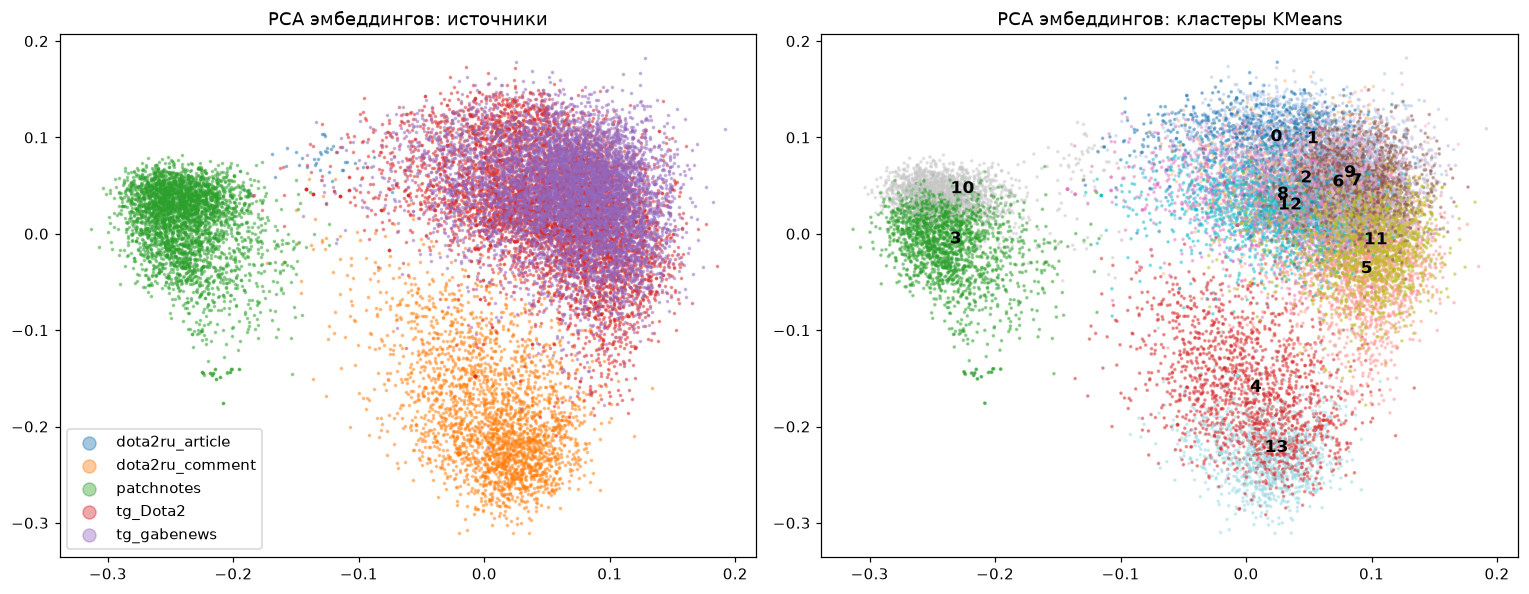

In [15]:
from sklearn.decomposition import PCA

xy = PCA(n_components=2, random_state=0).fit_transform(emb)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for src_name, g in df.groupby("source"):
    axes[0].scatter(xy[g.index, 0], xy[g.index, 1], s=2, alpha=0.4, label=src_name)
axes[0].legend(markerscale=6)
axes[0].set_title("PCA эмбеддингов: источники")
axes[1].scatter(xy[:, 0], xy[:, 1], c=df["cluster"], s=2, alpha=0.4, cmap="tab20")
for c in range(K):
    cx, cy = xy[df["cluster"] == c].mean(axis=0)
    axes[1].text(cx, cy, str(c), fontsize=11, weight="bold")
axes[1].set_title("PCA эмбеддингов: кластеры KMeans")
plt.tight_layout()

Примеры документов из каждого кластера:

In [16]:
for c in clusters.sort_values("docs", ascending=False).index:
    s = df[df["cluster"] == c].sample(2, random_state=0)
    print(f"--- кластер {c}: {clusters.loc[c, 'top_terms'][:80]}")
    for _, r in s.iterrows():
        print(f"  [{r['source']}] {r['visible'][:160]}")

--- кластер 3: патч, уменьшен, увеличен, уменьшена, увеличена, урон, секунд, золота, бонус, ман
  [patchnotes] Патч 7.34e — Dazzle - Bad Juju: способность больше не влияет на трёхсекундное отключение предмета Blink Dagger и его улучшений при получении урона
  [patchnotes] Патч 7.34d — Occult Bracelet - Бонус к восстановлению маны за эффект уменьшен с 0,5 до 0,4
--- кластер 7: team, betboom, international, турнир, tundra, состав, команды, дайджест, команда
  [tg_gabenews] 🇷🇺 Изменение EPT-рейтинга после DreamLeague S28 — 🇪🇺 Tundra , 🇷🇺 Aurora и 🇨🇳 Xtreme в ТОП-3. ☝️ Именно по этому списку выдаются инвайты на турниры от ESL и на E
  [tg_gabenews] 🏆 Riyadh Masters 2024 | Плей-офф | День 4 👀 Сегодня день матчей СНГ-команд — болеем за Spirit и BB Team всеми силами! ☝️ Расписание на весь день ✝️ Gabe News | 
--- кластер 12: баг, героя, который, сет, использовать, нужно, предмет, знали, работает, аспекто
  [tg_Dota2] ✍️ ✍️ Ночью вышло обновление — пофиксили кучу багов Убран кастрендж у Magic 

## 6. Сводка цифр для выводов

In [17]:
summary = {
    "документов": len(df),
    "токенов видимого текста (BGE-M3)": int(df["tok_visible"].sum()),
    "токенов сырого текста": int(df["tok_raw"].sum()),
    "медиана длины, видимый": int(df["tok_visible"].median()),
    f"доля < {SHORT} токенов, %": round(stats.percent_where(df["tok_visible"], lambda v: v < SHORT), 1),
    f"доля > {LONG} токенов, %": round(stats.percent_where(df["tok_visible"], lambda v: v > LONG), 1),
    "удаляемого шума в сыром тексте, % токенов": round(share.loc["ВСЕГО", "удаляемый_шум_%"], 1),
    "чисел, % токенов": round(share.loc["ВСЕГО", "num"], 1),
    "точных дубликатов, %": round(exact["exact_dup"].mean() * 100, 1),
    "документов в near-dup парах, %": round(len(near_ids) / len(df) * 100, 1),
}
pd.Series(summary).to_frame("значение")

,значение
документов,19665.0
токенов видимого текста (BGE-M3),1887206.0
токенов сырого текста,9917946.0
"медиана длины, видимый",58.0
"доля < 50 токенов, %",41.1
"доля > 2000 токенов, %",0.2
"удаляемого шума в сыром тексте, % токенов",82.5
"чисел, % токенов",1.1
"точных дубликатов, %",2.2
"документов в near-dup парах, %",1.6


## 7. Выводы

**1. Типичный размер документа и разброс.** Распределение резко неоднородное, с тяжёлым хвостом:
медиана — 58 токенов видимого текста, стандартное отклонение ~600.
* Комментарии dota2.ru — медиана 21 токен, 84% короче 50 токенов (часто это реплика из пары слов: «+1», «Почему?»).
* Посты Telegram — медиана 57–80 токенов, длинных почти нет (максимум < 1000).
* Блоки патчноутов — медиана 54, но 46% короче 50 (одна правка одного предмета) и редкие крупные блоки
  (масштабные патчи 7.36/7.38/7.41 — до 2,2 тыс. токенов на героя).
* Статьи dota2.ru — всего 36 документов (0,2% корпуса), но 16% всех токенов видимого текста: медиана 3,3 тыс.,
  максимум 46 тыс. токенов, 30 из 36 длиннее 2000. Это полные пересказы патчноутов.

В итоге 41,1% документов короче 50 токенов, а длиннее 2000 — 33 документа (0,2%): 30 статей и 3 блока патчноутов.

**2. Основной шум.** Доли — в токенах BGE-M3, то есть в долях входного окна модели.
* **Удаляемый шум — 82,5% токенов сырого корпуса**, и почти весь он — HTML-разметка и HTML-сущности (79%):
  `<i class="emoji">`, `<b>`, `<a href>`, `<br>`, `&nbsp;`, обёртки комментариев. Поэтому сырой корпус
  в 5,3 раза длиннее видимого текста (9,9 млн токенов против 1,89 млн). В Telegram удаляемого шума 85–87%,
  в статьях — 84%, в комментариях — 59%, в патчноутах — 5% (они пришли из JSON почти чистыми).
* HTML-сущности (`&nbsp;`, `&quot;`, `&#8212;` …) есть в 331 документе. Их нужно декодировать, а не просто
  вырезать теги: иначе `&nbsp;` превращается в три ложных фрагмента и раздувает длины (на статьях — на ~20%).
* Остальной удаляемый шум мал по объёму, но встречается почти везде: ссылки — 2% токенов, но они есть
  в 92–93% постов Telegram (подпись канала, промо-ссылки); эмодзи — 1% токенов, но есть в 99,5–99,8% постов
  (рубрики-заголовки); декоративные спецсимволы — 0,6%.
* Числа — 1,1% токенов корпуса, но 11% токенов патчноутов, и это не шум, а суть правки
  («урон увеличен с 75 до 80»): при чистке их удалять нельзя. Пунктуация (1,7%) — тоже не шум.
* Шаблонный текст, который символьными правилами не ловится: подписи каналов («Gabe News | Dota 2», «@Dota2») —
  настолько частые, что без отдельного стоп-списка они занимают верх ключевых слов любого кластера Telegram;
  рубрики-шаблоны («Еженедельный мета-отчёт»); удалённые и пустые комментарии (только картинка или цитата).
* Скрытая реклама: регулярка по букмекерским словам находит лишь ~1% постов, но кластеризация выделила
  отдельный кластер (~1,6 тыс. постов, 97% — @gabenews) розыгрышей и промо бота-предиктора.
  Это тоже кандидат на фильтрацию в КТ 2.
* Дубликаты: 2,2% лишних точных копий (больше всего — шаблонные посты @Dota2 и «Данный комментарий был удалён»).
  Ещё 1,6% документов (167 пар) — почти-дубликаты с подтверждённым Jaccard ≥ 0,8: в основном отредактированные
  и перепощенные посты одного канала. Число пар выходит на плато уже при пороге кандидатов LSH 0,6
  (а при итоговом пороге 0,8 LSH нашёл бы лишь 156 из 167), поэтому оценка близка к полной.

**3. Тематические кластеры.** Эмбеддинги разделяют корпус прежде всего по **стилю источника** —
патчноуты, посты Telegram и комментарии почти не смешиваются в одном кластере, — а уже внутри по теме:
* правки баланса — патчноуты: цифры способностей и предметов, таланты (два кластера, 96–99% патчноутов);
* пересказы патчей в Telegram: аспекты, нейтральные предметы, скилпоинты — те же факты другим языком;
* выход и ожидание обновлений, разработчики Valve;
* турниры, составы и результаты; Team Spirit и её игроки; мнения про-игроков о керри-героях;
* статистика: винрейты по данным Dotabuff, регулярные мета-отчёты по MMR;
* баги, фишки и механики («знали об этом?»); контент стримеров вместе с косметикой и мастерской;
* розыгрыши и промо бота-предиктора;
* форум: развёрнутые обсуждения нерфов и короткие реакции, удалённые комментарии («апнули», «понерфили», «найс»).

**4. Проблемы для чанкинга и ретрива.**
* **Один размер чанка не подходит никому:** статьи надо резать, а 40% документов и так короче 50 токенов —
  фиксированный чанк в 512 токенов для них бессмыслен, а короткие комментарии без контекста статьи
  («что с ним») почти не несут информации — понадобятся метаданные (к какому патчу/статье относится).
* **Без удаления HTML и декодирования сущностей** 4/5 embedding-окна занято разметкой,
  а BM25 индексирует имена классов, атрибутов и обломки сущностей.
* **SentenceChunker** будет ошибаться на постах Telegram: предложения там разделены эмодзи, а не точками.
* **Шаблонные посты, подписи и дубликаты** будут занимать несколько мест в top-k одинаковым текстом;
  подписи каналов вдобавок сближают эмбеддинги несвязанных постов одного канала.
* **Один факт — несколько источников:** правка есть в патчноуте, в статье, в пересказе Telegram и
  в обсуждении. В gold-наборе нужно указывать все релевантные документы, иначе Recall занизится.
* **Разные формы имён:** в патчноутах (русская локализация Valve) имена героев и предметов английские
  (Pudge, Black King Bar), в постах и комментариях — русские и сленговые (Пудж, бкб).
  BM25 на этом будет проигрывать, dense-модели должны быть мультиязычными.
* **Временная неоднозначность:** одна и та же способность меняется в нескольких патчах 7.34–7.41,
  поэтому вопросы без указания патча неоднозначны, а фильтрация по метаданным (патч, дата) должна помогать.